# 🚀 Модуль 4. Урок 2. Дубликаты, строковые аномалии и регулярные выражения (Regex)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_04_data_cleaning/lesson_02_duplicates_string_cleaning_regex.ipynb)

## 📌 Бизнес-контекст и методология
В CRM и транзакционных системах один и тот же город или товар могут быть записаны десятками способов: «Москва», «г. Москва», «г.Москва», «MSK», «москва». 
Если аналитик сделает `GROUP BY city`, компания увидит 5 мелких сегментов вместо одного крупного рынка. 
Стандартизация строк и выявление дубликатов с помощью регулярных выражений — базовый навык очистки данных.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем типовой хаос в написании городов и очистим его регулярными выражениями.

In [2]:
# Грязный список городов от пользователей
raw_cities = [
    'Москва', ' г. Москва ', 'МОСКВА', 'г.москва', 'MSK',
    'Санкт-Петербург', 'СПб', 'г. Санкт-Петербург', 'питер', 'SPB',
    'Новосибирск', 'г. Новосибирск', 'НСК', 'новосибирск '
] * 50

df_cities = pd.DataFrame({'city_raw': raw_cities})
print(f"Уникальных вариантов написания ДО очистки: {df_cities['city_raw'].nunique()}")

Уникальных вариантов написания ДО очистки: 14


### 📊 Визуализация: До и После нормализации строк
Графики ниже наглядно показывают, как дробление одной сущности на 13 вариантов искажает аналитику, и как Regex превращает хаос в 3 четких кластера.

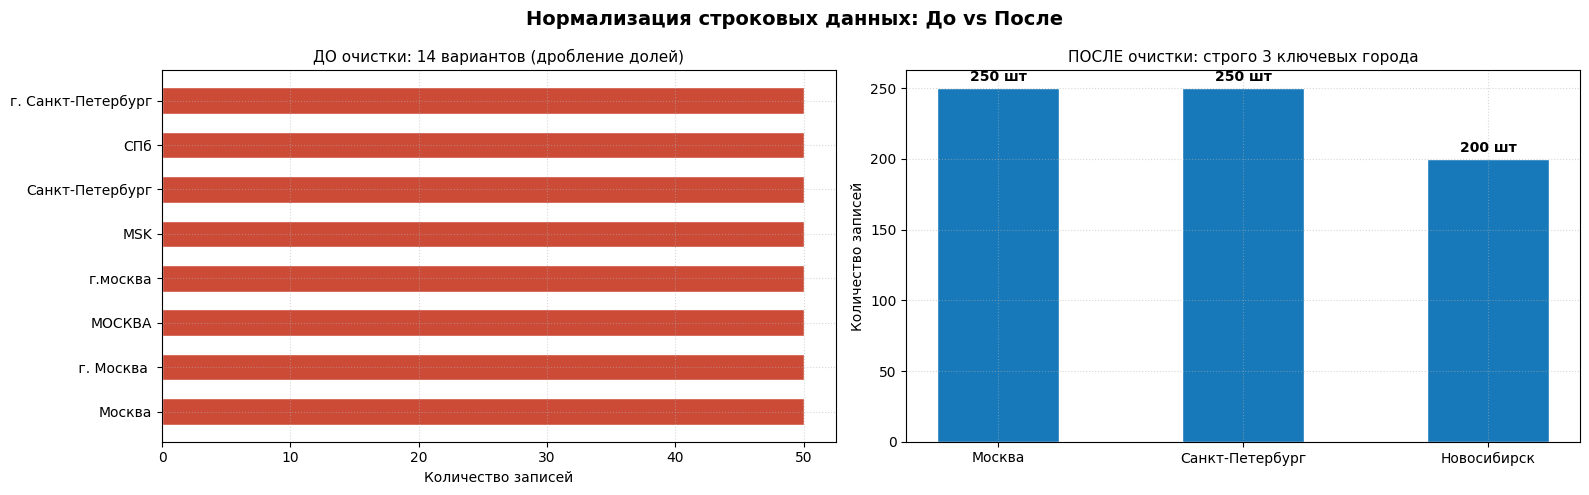

In [3]:
import re
import matplotlib.pyplot as plt

def standardize_city(text):
    text = str(text).lower().strip()
    text = re.sub(r'^г\.?\s*', '', text)  # убираем "г." или "г. "
    if 'москв' in text or 'msk' in text:
        return 'Москва'
    elif 'петербург' in text or 'спб' in text or 'питер' in text or 'spb' in text:
        return 'Санкт-Петербург'
    elif 'новосибирск' in text or 'нск' in text:
        return 'Новосибирск'
    return text.capitalize()

df_cities['city_clean'] = df_cities['city_raw'].apply(standardize_city)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Нормализация строковых данных: До vs После', fontsize=14, fontweight='bold')

# 1. ДО очистки (хаос)
ax1 = axes[0]
top_dirty = df_cities['city_raw'].value_counts().head(8)
ax1.barh(top_dirty.index, top_dirty.values, color='#cc4b37', edgecolor='white', height=0.6)
ax1.set_title(f'ДО очистки: {df_cities["city_raw"].nunique()} вариантов (дробление долей)', fontsize=11)
ax1.set_xlabel('Количество записей')
ax1.grid(True, linestyle=':', alpha=0.5)

# 2. ПОСЛЕ очистки (четкие кластеры)
ax2 = axes[1]
clean_counts = df_cities['city_clean'].value_counts()
bars2 = ax2.bar(clean_counts.index, clean_counts.values, color='#1779ba', edgecolor='white', width=0.5)
ax2.set_title(f'ПОСЛЕ очистки: строго {df_cities["city_clean"].nunique()} ключевых города', fontsize=11)
ax2.set_ylabel('Количество записей')
ax2.grid(True, linestyle=':', alpha=0.5)

for b in bars2:
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2, h + 5, f'{h} шт', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Очистка телефонных номеров с помощью Regex
Нормализуйте телефонные номера к единому формату `+7XXXXXXXXXX` (уберите скобки, тире, пробелы и замените ведущую `8` на `+7`).

In [4]:
### ВАШ КОД ЗДЕСЬ
phone_raw = pd.Series(['8 (999) 123-45-67', '+7 999 123 45 67', '89991234567', '+7(999)1234567'])

def clean_phone(p):
    digits = re.sub(r'\D', '', p)
    if digits.startswith('8'):
        digits = '7' + digits[1:]
    return '+' + digits

phone_clean = phone_raw.apply(clean_phone)
print("Очищенные телефоны:")
print(phone_clean)

assert all(phone_clean == '+79991234567'), "Все телефоны должны иметь формат +79991234567"
print("✅ Тест успешно пройден!")

Очищенные телефоны:
0    +79991234567
1    +79991234567
2    +79991234567
3    +79991234567
dtype: str
✅ Тест успешно пройден!


### 💼 Когда Regex незаменим:
1. Очистка UTM-меток в веб-аналитике.
2. Извлечение артикулов и SKU из названий товаров.
3. Валидация email-адресов и телефонов перед загрузкой в DWH.